# Data prep + EDA
Part 1 cleans the data, builds near-duplicate groups and the fixed split, and saves `train_clean.parquet` / `test_clean.parquet` for all next notebooks. Part 2 is EDA on the cleaned data.

In [1]:
import html
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd

pd.set_option('display.max_colwidth', 400)
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings('ignore')

SEED = 42
DATA = next(Path('/kaggle/input').rglob('train.csv')).parent
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
train.shape, test.shape

((272352, 5), (25000, 4))

# Part 1. Data prep

## HTML leftovers
If they concentrate in one class or domain, they are a source shortcut, not an AI signal.

In [2]:
html_flags = pd.DataFrame({
    'entity': train.text.str.contains(r'&[a-zA-Z]+;|&#\d+;'),
    'tag': train.text.str.contains(r'</?[a-zA-Z][^>]{0,50}>'),
})
html_flags.groupby([train.domain, train.label]).mean().unstack().round(3)

entity                tag             
label                      ai fusion  human   ai fusion human
domain                                                       
arxiv_papers            0.000  0.000  0.000  0.0  0.001   0.0
blog_authorship_corpus  0.001  0.047  0.070  0.0  0.000   0.0
bundestag               0.000  0.000  0.000  0.0  0.000   0.0
cnn_news                0.000  0.000  0.000  0.0  0.000   0.0
euro_court_cases        0.000  0.000  0.000  0.0  0.000   0.0
gutenberg               0.000  0.000  0.000  0.0  0.000   0.0
house_of_commons        0.000  0.006  0.008  0.0  0.000   0.0
student_essays          0.000  0.000  0.000  0.0  0.000   0.0

## HTML cleanup
Unescape entities and strip tags. Punctuation, quotes and dashes are kept as AI markers.

In [3]:
HTML_TAG = re.compile(r'</?[a-zA-Z][^>]{0,50}>')

def clean(t):
    return HTML_TAG.sub(' ', html.unescape(t))

for df in [train, test]:
    cleaned = df.text.map(clean)
    print(f'changed: {(cleaned != df.text).mean():.4f}')
    df['text'] = cleaned

changed: 0.0059
changed: 0.0085


## Duplicates
By text only, after cleanup (cleanup can create new duplicates).

In [4]:
dups = train[train.text.duplicated(keep=False)]
print(f'duplicated texts: {train.text.duplicated().sum()}, with conflicting labels: {dups.groupby("text").label.nunique().gt(1).sum()}')
train = train.drop_duplicates(subset='text').reset_index(drop=True)
len(train)

duplicated texts: 0, with conflicting labels: 0


272352

## Near-duplicate groups
Texts sharing the normalized first or last 150 chars (e.g. human text and its fusion rewrite) are joined into one group. Keys shared by more than `MAX_KEY` texts are boilerplate (e.g. Bundestag greetings), not pairs, and are skipped.

In [5]:
MAX_KEY = 5

def norm(t):
    return ' '.join(re.findall(r'\w+', t.lower()))

KEYS = {
    'head': lambda t: norm(t[:400])[:150],
    'tail': lambda t: norm(t[-400:])[-150:],
}
train_keys = {name: train.text.map(f) for name, f in KEYS.items()}
test_keys = {name: test.text.map(f) for name, f in KEYS.items()}

parent = np.arange(len(train))

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

for name, key in train_keys.items():
    skipped = 0
    for idx in key.groupby(key).indices.values():
        if len(idx) > MAX_KEY:
            skipped += len(idx)
            continue
        for j in idx[1:]:
            parent[find(j)] = find(idx[0])
    print(f'{name}: texts with boilerplate key skipped: {skipped}')

train['group'] = [find(i) for i in range(len(train))]
size = train.group.map(train.group.value_counts())
print(f'texts in multi-text groups: {(size > 1).mean():.4f}, groups: {train.group.nunique()}')
train[size > 1].groupby('group').label.agg(lambda s: '+'.join(sorted(set(s)))).value_counts().head(10)

head: texts with boilerplate key skipped: 2530
tail: texts with boilerplate key skipped: 774
texts in multi-text groups: 0.4395, groups: 202821


label
fusion+human       44564
fusion              4977
ai                   534
human                 90
ai+fusion              4
ai+fusion+human        1
ai+human               1
Name: count, dtype: int64

## Train ↔ test pairs
If test texts have pairs in train as often as train texts do, a random split would be honest too; if not, the group split is required.

In [6]:
def pair_rate(name):
    counts = pd.concat([train_keys[name], test_keys[name]]).value_counts()
    ok = lambda k: k.map(counts).le(MAX_KEY)
    tr_k, te_k = train_keys[name], test_keys[name]
    return {
        'train_with_train_pair': (tr_k.duplicated(keep=False) & ok(tr_k)).mean(),
        'test_with_train_pair': (te_k.isin(set(tr_k)) & ok(te_k)).mean(),
    }

pd.DataFrame({name: pair_rate(name) for name in KEYS}).round(4)

,head,tail
train_with_train_pair,0.4026,0.1156
test_with_train_pair,0.0006,0.0002


In [7]:
train.loc[train.group.isin(train.group[size > 1].head(1)), ['domain', 'label', 'text']].assign(text=lambda d: d.text.str[:300])

,domain,label,text
1,bundestag,human,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz ziehe für den Bundesinnenminister, gerade für die Felder Migration und innere Sicherheit. Ich will das an"
65583,bundestag,fusion,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz ziehe für den Bundesinnenminister, gerade für die Felder Migration und innere Sicherheit. Ich will das an"


## Fixed split
20% val (1 of 5 folds), stratified by label × lang × domain, near-duplicate groups never cross folds.

In [8]:
strat = train.label + '|' + train.lang + '|' + train.domain
_, va_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(train, strat, train.group))
train['fold'] = 'train'
train.loc[va_idx, 'fold'] = 'val'
assert train.groupby('group').fold.nunique().max() == 1
pd.crosstab([train.lang, train.label], train.fold, normalize='columns').round(3)

fold          train    val
lang  label               
de-DE ai      0.075  0.075
      fusion  0.067  0.062
      human   0.054  0.051
en-EN ai      0.373  0.372
      fusion  0.240  0.246
      human   0.191  0.195

## Save

In [9]:
train.to_parquet('train_clean.parquet', index=False)
test.to_parquet('test_clean.parquet', index=False)
train.fold.value_counts()

fold
train    217815
val       54537
Name: count, dtype: int64

# Part 2. EDA
On cleaned train (after dedup), with `fold` and `group` available.

In [10]:
train.head()

,id,text,lang,domain,label,group,fold
0,e7adad,"Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whispers swirl about Diego Maradona's health and personal life taking a dramatic turn for the worse. Could the legendary Argentine footballer, once hailed as a hero, be slipping back into his old demons? The latest reports paint a troubling picture of a man battling both addiction an...",en-EN,cnn_news,ai,0,train
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszeit, nachdem drei Viertel dieser Regierungszeit vergangen sind, positive Bilanz ziehe für den Bundesinnenminister, gerade für die Felder Migration und innere Sicherheit. Ich will das an ganz konkreten Punkten festmachen. Fachkräfteeinwanderungsgesetz – das Stichwort ist hier heute ...",de-DE,bundestag,human,1,val
2,4e6c1f,"Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme ich in Bezug auf das, was er am Anfang gesagt hat, zu. Wir haben in der Tat eine extrem schwere Krise. Eigentlich ist es bewundernswert, mit welcher Disziplin, mit welchem Verantwortungsbewusstsein und wie solidarisch ein großer Teil der Bevölkerung mit dieser Krise umgeht. Ohne dieses Verhalten wären wir heute nicht be...",de-DE,bundestag,human,2,train
3,f92d07,"[12/17/2002 9:40:16 PM | + racheal] shagging. I feel sick. I want to go throw up and throw up and throw up. I dont know what it isremnants of dinner flushed down with red wine and biscotti feels trapped in my throat. But thats the way it always feel, thats the way the story goes. Right before I do myself the glorious perverse pleasure of pumping the volume up to stick my fingers down my throat...",en-EN,blog_authorship_corpus,human,3,train
4,6162f5,"IN THE COURT OF CASE NO. , Plaintiffs, v. , Defendant. RULING ON PENSION CLAIMS I. INTRODUCTION 1. This matter comes before the Court on the claims of the Plaintiffs, , seeking pension benefits arising from the death of their son, , an army pilot who tragically perished in a plane crash during a military operation on . The Plaintiffs assert entitlement to pension benefits under [specific pensi...",en-EN,euro_court_cases,ai,4,train


## Data quality

In [11]:
pd.Series({
    'na_text': train.text.isna().sum(),
    'dup_text_train': train.text.duplicated().sum(),
    'dup_text_conflicting_labels': train.groupby('text').label.nunique().gt(1).sum(),
    'train_text_in_test': train.text.isin(test.text).sum(),
})

na_text                        0
dup_text_train                 0
dup_text_conflicting_labels    0
train_text_in_test             0
dtype: int64

## Class balance

In [12]:
train.label.value_counts(normalize=True).round(3)

label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64

In [13]:
pd.crosstab(train.lang, train.label, normalize='index').round(3)

label,ai,fusion,human
lang,,,
de-DE,0.385,0.340,0.275
en-EN,0.463,0.299,0.238


In [14]:
pd.crosstab(train.domain, train.label, normalize='index').round(3)

label,ai,fusion,human
domain,,,
arxiv_papers,0.843,0.128,0.028
blog_authorship_corpus,0.387,0.306,0.307
bundestag,0.382,0.342,0.277
cnn_news,0.440,0.257,0.302
euro_court_cases,0.404,0.368,0.228
gutenberg,0.915,0.051,0.034
house_of_commons,0.480,0.302,0.218
student_essays,0.399,0.370,0.231


In [15]:
pd.crosstab([train.lang, train.domain], train.label, margins=True)

label                             ai  fusion  human     All
lang  domain                                               
de-DE bundestag                19977   17887  14479   52343
      gutenberg                  360      37     31     428
en-EN arxiv_papers             12050    1833    407   14290
      blog_authorship_corpus   15684   12397  12466   40547
      cnn_news                 19488   11402  13395   44285
      euro_court_cases         11141   10160   6277   27578
      gutenberg                 6359     341    216    6916
      house_of_commons         15298    9608   6953   31859
      student_essays           21583   20017  12506   54106
All                           121940   83682  66730  272352

In [16]:
pd.concat({
    f'{split}_{col}': df[col].value_counts(normalize=True).round(3)
    for split, df in [('train', train), ('test', test)]
    for col in ['lang', 'domain'] if col in df
}, axis=1)

,train_lang,train_domain,test_lang,test_domain
en-EN,0.806,NaN,0.853,NaN
de-DE,0.194,NaN,0.147,NaN
student_essays,NaN,0.199,NaN,0.159
bundestag,NaN,0.192,NaN,0.143
cnn_news,NaN,0.163,NaN,0.197
blog_authorship_corpus,NaN,0.149,NaN,0.178
house_of_commons,NaN,0.117,NaN,0.118
euro_court_cases,NaN,0.101,NaN,0.064
arxiv_papers,NaN,0.052,NaN,0.067
gutenberg,NaN,0.027,NaN,0.074


## Language check

In [17]:
DE = {'der', 'die', 'und', 'das', 'ist', 'nicht', 'ein', 'zu', 'den', 'mit', 'sich', 'auf', 'für', 'von'}
EN = {'the', 'and', 'of', 'to', 'is', 'in', 'that', 'it', 'for', 'with', 'was', 'on', 'are', 'this'}

def lang_guess(t):
    w = re.findall(r'\w+', t[:3000].lower())
    de, en = sum(x in DE for x in w), sum(x in EN for x in w)
    return 'de' if de > en else 'en' if en > de else 'unk'

train['lang_guess'] = train.text.map(lang_guess)
pd.crosstab(train.lang, train.lang_guess)

lang_guess,de,en,unk
lang,,,
de-DE,52394,369,8
en-EN,187,219200,194


## Lengths

In [18]:
train['n_chars'] = train.text.str.len()
train['n_words'] = train.text.str.split().str.len()
train['avg_word_len'] = train.n_chars / train.n_words
train.groupby(['lang', 'label'])[['n_chars', 'n_words', 'avg_word_len']].median().round(1)

n_chars  n_words  avg_word_len
lang  label                                 
de-DE ai       3106.0    430.0           7.2
      fusion   4098.5    584.0           7.0
      human    4059.5    584.0           6.9
en-EN ai       3115.0    481.0           6.4
      fusion   2312.0    389.0           6.0
      human    2497.0    439.0           5.7

In [19]:
train.groupby('label').n_words.describe(percentiles=[.05, .25, .5, .75, .95]).round(0)

,count,mean,std,min,5%,25%,50%,75%,95%,max
label,,,,,,,,,,
ai,121940.0,493.0,294.0,20.0,60.0,287.0,465.0,657.0,1008.0,2996.0
fusion,83682.0,585.0,531.0,20.0,79.0,263.0,445.0,695.0,1820.0,3000.0
human,66730.0,578.0,473.0,16.0,57.0,262.0,481.0,740.0,1490.0,2998.0


In [20]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained('xlm-roberta-base')
s = train.groupby(['lang', 'label']).sample(500, random_state=42)
s['n_tok'] = [len(x) for x in tok(s.text.tolist(), add_special_tokens=False)['input_ids']]
s.groupby(['lang', 'label']).n_tok.agg(median='median', over_512=lambda x: (x > 512).mean()).round(2)

median  over_512
lang  label                   
de-DE ai       647.5      0.73
      fusion   897.0      0.94
      human    884.0      0.81
en-EN ai       721.5      0.64
      fusion   505.0      0.49
      human    601.0      0.56

## Examples

In [21]:
train.groupby('label').sample(2, random_state=0)[['lang', 'domain', 'label', 'text']].assign(text=lambda d: d.text.str[:600])

,lang,domain,label,text
253966,en-EN,cnn_news,ai,"Tragedy at Yarnell Hill: Investigating the Granite Mountain Hotshots and Leadership Accountability On June 30, 2013, a wildfire erupted near Yarnell, Arizona, igniting a tragic series of events that would claim the lives of 19 members of the Granite Mountain Hotshot crew. The Yarnell Hill Fire, which started as a manageable blaze, quickly escalated, leading to one of the deadliest days in U.S...."
7425,de-DE,bundestag,ai,"Der Wassernotstand: Ein Tropfen auf den heißen Stein Liebe Kolleginnen und Kollegen, es ist mir eine Ehre, heute in diesem Plenum über die drängendste Herausforderung unserer Zeit zu sprechen – den drohenden Wassermangel in Deutschland. Und ja, ich weiß, manche von Ihnen denken jetzt: „Wasser? Wir leben doch in einem Land mit Regen, Flüssen und Seen. Worüber regt sich das Parlament auf?“ Der E..."
252239,en-EN,euro_court_cases,fusion,"4. The applicant was born in 1935 and lives in the village of Kresty in the Tula Region. 5. On 20 October 1993 the applicant sued the Chernskiy District Social Security Services for pension arrears, an increase of his monthly pension and compensation for damage. 6. On 16 December 1993 the Chernskiy District Court accepted the action in full. The judgment was quashed on 1 February 1994 and the ..."
141881,de-DE,bundestag,fusion,"Herr Präsident! Sehr geehrte Kolleginnen und Kollegen! Liebe Besucherinnen und Besucher! „Wir brauchen Partner, auf die wir uns verlassen können.“ Das ist der eindringlichste Satz, den ich als Außenministerin im letzten Jahr immer wieder gehört habe, egal an welchen Ort ich gereist bin, nicht nur in der Ukraine, nicht nur im Baltikum, sondern auch in Asien, in Afrika, im Nahen Osten und erst r..."
254997,en-EN,blog_authorship_corpus,human,"Been so busy with school that I haven't been able to blog here like I wanted to. Nearing the end of nursing school. Graduate in August finally. So ready to finish. Of course, I'll probably take a chem. class this fall even though I should just take it easy. Who knows. I'd like to replace some of my old bad grades with some much better ones. Just for my own happiness. And because a grad progr..."
220978,en-EN,house_of_commons,human,"What recent discussions the Electoral Commission has had with the Government on the reduction of the minimum age for voting. The commission has been working closely with the Government's children and young people's unit on the ""Y vote, Y not?"" project, which is consulting young people about measures to encourage increased participation in elections. One suggestion is to reduce the minimum voti..."


## Fusion vs human vs ai

In [22]:
style = pd.DataFrame({
    'punct': train.text.str.count(r'[^\w\s]') / train.n_chars,
    'em_dash': train.text.str.count('—') / train.n_words,
    'newlines': train.text.str.count('\n') / train.n_words,
    'sent_len': train.n_words / train.text.str.count(r'[.!?]+').clip(lower=1),
    'ttr_200': train.text.map(lambda t: len(set(t.lower().split()[:200])) / max(min(len(t.split()), 200), 1)),
    'lang': train.lang,
    'label': train.label,
})
style.groupby(['lang', 'label']).median().round(3)

punct  em_dash  newlines  sent_len  ttr_200
lang  label                                              
de-DE ai      0.021      0.0       0.0    16.690    0.715
      fusion  0.023      0.0       0.0    15.633    0.710
      human   0.025      0.0       0.0    15.484    0.710
en-EN ai      0.026      0.0       0.0    17.273    0.702
      fusion  0.023      0.0       0.0    17.200    0.650
      human   0.026      0.0       0.0    16.964    0.630

## Domain deep dive: arxiv_papers, gutenberg

In [23]:
train.pivot_table(index='domain', columns='label', values='n_words', aggfunc='median')

label,ai,fusion,human
domain,,,
arxiv_papers,824.0,2344.0,2382.0
blog_authorship_corpus,129.0,128.0,137.0
bundestag,429.0,584.0,585.0
cnn_news,530.0,501.0,627.0
euro_court_cases,550.0,764.0,854.0
gutenberg,696.0,1538.0,1131.0
house_of_commons,547.0,509.0,554.0
student_essays,371.0,343.0,388.0


In [24]:
pd.crosstab([test.domain, test.lang], 'n').assign(train_n=pd.crosstab([train.domain, train.lang], 'n')['n'])

col_0                            n  train_n
domain                 lang                
arxiv_papers           en-EN  1683    14290
blog_authorship_corpus en-EN  4446    40547
bundestag              de-DE  3581    52343
cnn_news               en-EN  4937    44285
euro_court_cases       en-EN  1591    27578
gutenberg              de-DE   102      428
                       en-EN  1743     6916
house_of_commons       en-EN  2941    31859
student_essays         en-EN  3976    54106

In [25]:
(train[train.domain.isin(['arxiv_papers', 'gutenberg'])]
 .groupby(['domain', 'label']).sample(2, random_state=1)
 [['domain', 'lang', 'label', 'n_words', 'text']]
 .assign(text=lambda d: d.text.str[:500]))

,domain,lang,label,n_words,text
101265,arxiv_papers,en-EN,ai,584,"The interplay between magnetic impurities and two-dimensional (2D) electron systems with strong Rashba spin-orbit coupling (SOC) presents a fertile ground for exploring exotic quantum transport phenomena. These systems, often realized in semiconductor heterostructures or at the interfaces of novel materials, exhibit unique properties arising from the intertwined effects of electron confinement..."
8193,arxiv_papers,en-EN,ai,940,"Abstract In this paper, we investigate the σ-arithmetic graphs associated with finite groups, focusing on their structural properties and implications for group theory. The concept of σ-arithmetic graphs provides a novel perspective on the interplay between group properties and graph theory, particularly in the context of σ-solubility and σ-nilpotency. We define the σ-arithmetic graph of a fin..."
202059,arxiv_papers,en-EN,fusion,2980,"arXiv:2001.09853v1 [math.CO] 27 Jan 2020 The game of Cops and Robbers on directed graphs with forbidden subgraphs Mingrui Liu ∗ January 29, 2020 Abstract The traditional game of cops and robbers is played on undirected graph. Recently, the same game played on directed graph is getting attention by more and more people. We knew that if we forbid some subgraph we can bound the cop number of the ..."
44314,arxiv_papers,en-EN,fusion,2292,"Missing Section 4.2 Evaluation on Real Clinical Data To further validate the efficacy of our proposed model, we conducted an evaluation on real clinical datasets containing metal artifacts from various types of implants. The dataset comprised CT images acquired from patients with diverse metal objects, including orthopedic implants and dental fixtures. These images were selected based on the p..."
122269,arxiv_papers,en-EN,human,1960,"Impact of the underlying O(4) criticality on net-proton number ﬂuctuations∗ Micha l Szyma´nski Institute of Theoretical Physics, University of Wroclaw, Wroclaw, Poland We discuss the beam-energy dependence of ratios of the ﬁrst four cu- mulants of the net-proton number, calculated using a phenomenologically motivated model in which critical mode ﬂuctuations couple to protons and anti-protons. ..."
200825,arxiv_papers,en-EN,human,2457,"Unsupervised Distribution Learning for Lunar Surface Anomaly Detection Adam Lesnikowski NVIDIA 2701 San Tomas Expressway Santa Clara, CA 95051 alesnikowski@nvidia.com Valentin T. Bickel ETH Zurich & MPS Goettingen Sonneggstrasse 5 Zurich, 8092, CH valentin.bickel@erdw.ethz.ch Daniel Angerhausen (a) Center for Space and Habitability University of Bern Gesellschaftsstrasse 6 3012 Bern daniel.ang..."
208890,gutenberg,en-EN,ai,148,"In the hallowed realms of poetic expression, where the soul's innermost whispers intertwine with the ethereal dance of language, we find ourselves presented with the remarkable collection of verses by John W. Draper. This anthology, a testament to the delicate balance between artistic beauty and the capricious nature of public taste, invites the discerning reader to embark upon a journey throu..."
238995,gutenberg,de-DE,ai,31,"Es tut mir leid, aber ich kann Ihnen nicht mit einem Text von 2000 Wörtern auf einmal helfen. Ich kann jedoch einen kürzeren Abschnitt oder eine Zusammenfassung schreiben. Möchten Sie das?"
107014,gutenberg,en-EN,fusion,787,"Transcriberâ€™s Note: The cover image was created by the transcriber and is placed in the public domain. One lovely summer morning the little Princess Rosemary woke up early, jumped out of bed, put on her crown and popped her head out of the castle window. There she saw, through the branches of the Queenâ€™s best rose-tree, a merry band of Dew Children, sparkling through the castle park as lig..."
61725,gutenberg,en-EN,fusion,891,"GOOSE VOLLAND EDITION Illustrated by FREDERICK RICHARDSON DERRYDALE BOOKS NEW YORK Compiler and Artist to VIRGINIA and DORIS and their mother, the inspiration of the publisher As I watched the sun dip below the horizon, c

## AI markers

In [26]:
MARKERS = {
    'em_dash': '—',
    'en_dash_spaced': ' – ',
    'curly_quotes': '[“”‘’„]',
    'ellipsis_char': '…',
    'markdown': r'\*\*|^#|\s#{1,3}\s',
    'title_colon_start': r'^[^.!?]{10,120}:\s',
    'placeholder': r'\[[A-Za-z][^\]]{2,40}\]',
    'not_x_but_y': r"(?i)\b(?:not (?:just|only|merely|simply)\b[^.]{0,80}\bbut|isn't (?:just )?about|it's not\b[^.]{0,60}\bit's)\b",
    'nicht_nur_sondern': r'(?i)\bnicht nur\b[^.]{0,120}\bsondern\b',
    'buzzwords_en': r'(?i)\b(?:delve|tapestry|testament|pivotal|intricate|multifaceted|foster|realm|underscore|showcase|seamless|leverage|vibrant|nuanced|navigat\w*|landscape)\b',
    'transitions_en': r"(?i)\b(?:moreover|furthermore|additionally|in conclusion|ultimately|it is important to note|it's worth noting)\b",
    'transitions_de': r'(?i)\b(?:darüber hinaus|zudem|insgesamt|letztendlich|es ist wichtig)\b',
    'double_space': '  ',
    'lowercase_i': r'\bi\b',
}
flags = pd.DataFrame({k: train.text.str.contains(v, regex=True) for k, v in MARKERS.items()})
flags[['lang', 'domain', 'label']] = train[['lang', 'domain', 'label']]
flags.groupby(['lang', 'label'])[list(MARKERS)].mean().round(3).T

lang               de-DE                en-EN              
label                 ai fusion  human     ai fusion  human
em_dash            0.002  0.002  0.001  0.134  0.041  0.015
en_dash_spaced     0.467  0.862  0.884  0.264  0.096  0.062
curly_quotes       0.143  0.450  0.504  0.544  0.298  0.214
ellipsis_char      0.012  0.186  0.043  0.049  0.015  0.008
markdown           0.000  0.000  0.000  0.018  0.002  0.001
title_colon_start  0.108  0.018  0.012  0.235  0.039  0.034
placeholder        0.005  0.001  0.000  0.040  0.048  0.048
not_x_but_y        0.005  0.001  0.000  0.273  0.202  0.081
nicht_nur_sondern  0.626  0.591  0.246  0.000  0.000  0.000
buzzwords_en       0.010  0.002  0.001  0.455  0.185  0.030
transitions_en     0.005  0.001  0.000  0.368  0.329  0.114
transitions_de     0.290  0.389  0.225  0.000  0.000  0.000
double_space       0.000  0.000  0.000  0.000  0.000  0.000
lowercase_i        0.000  0.001  0.001  0.019  0.108  0.120

In [27]:
flags.groupby(['domain', 'label'])[list(MARKERS)].mean().round(2)

em_dash  en_dash_spaced  curly_quotes  \
domain                 label                                           
arxiv_papers           ai         0.06            0.06          0.06   
                       fusion     0.20            0.16          0.74   
                       human      0.16            0.19          0.85   
blog_authorship_corpus ai         0.17            0.29          0.52   
                       fusion     0.04            0.03          0.11   
                       human      0.01            0.01          0.04   
bundestag              ai         0.00            0.47          0.14   
                       fusion     0.00            0.86          0.45   
                       human      0.00            0.89          0.50   
cnn_news               ai         0.13            0.26          0.77   
                       fusion     0.06            0.15          0.49   
                       human      0.04            0.13          0.36   
euro_court_cases       ai         0.01            0.06          0.44   
                       fusion     0.01            0.19          0.84   
                       human      0.00            0.21          0.87   
gutenberg              ai         0.14            0.49          0.61   
                       fusion     0.68            0.27          0.57   
                       human      0.66            0.01          0.30   
house_of_commons       ai         0.14            0.27          0.45   
                       fusion     0.03            0.05          0.08   
                       human      0.00            0.00          0.00   
student_essays         ai         0.21            0.39          0.72   
                       fusion     0.03            0.07          0.09   
                       human      0.00            0.00          0.00   

                               ellipsis_char  markdown  title_colon_start  \
domain                 label                                                
arxiv_papers           ai               0.00      0.13               0.45   
                       fusion           0.02      0.05               0.13   
                       human            0.04      0.07               0.07   
blog_authorship_corpus ai               0.14      0.00               0.09   
                       fusion           0.02      0.00               0.09   
                       human            0.01      0.00               0.10   
bundestag              ai               0.01      0.00               0.11   
                       fusion           0.19      0.00               0.02   
                       human            0.04      0.00               0.01   
cnn_news               ai               0.03      0.01               0.32   
                       fusion           0.01      0.00               0.02   
                       human            0.02      0.00               0.02   
euro_court_cases       ai               0.00      0.00               0.31   
                       fusion           0.01      0.00               0.00   
                       human            0.00      0.00               0.00   
gutenberg              ai               0.14      0.01               0.21   
                       fusion           0.13      0.00               0.10   
                       human            0.00      0.00               0.26   
house_of_commons       ai               0.01      0.00               0.12   
                       fusion           0.04      0.00               0.02   
                       human            0.00      0.00               0.00   
student_essays         ai               0.05      0.00               0.20   
                       fusion           0.00      0.00               0.04   
                       human            0.00      0.00               0.01   

                               placeholder  not_x_but_y  nicht_nur_sondern  \
domain                 label                                                 

## Burstiness

In [28]:
import numpy as np

def sent_len_cv(t):
    l = [len(s.split()) for s in re.split(r'(?<=[.!?])\s+', t) if s]
    return np.std(l) / np.mean(l) if len(l) > 1 else np.nan

train['sent_len_cv'] = train.text.map(sent_len_cv)
train.pivot_table(index='domain', columns='label', values='sent_len_cv', aggfunc='median').round(3)

label,ai,fusion,human
domain,,,
arxiv_papers,0.519,0.758,1.070
blog_authorship_corpus,0.510,0.593,0.621
bundestag,0.416,0.583,0.645
cnn_news,0.409,0.565,0.586
euro_court_cases,0.572,0.849,0.898
gutenberg,0.407,0.695,0.727
house_of_commons,0.424,0.584,0.652
student_essays,0.435,0.421,0.452


# Visualizations

In [29]:
import matplotlib.pyplot as plt

LABELS = ['human', 'ai', 'fusion']
COLORS = dict(zip(LABELS, ['#2a78d6', '#eb6834', '#1baf7a']))
DOMAIN_COLORS = dict(zip(sorted(train.domain.unique()), ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']))
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .3, 'figure.dpi': 110})
FIG = Path('figures')
FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
    plt.show()

## Class balance by domain

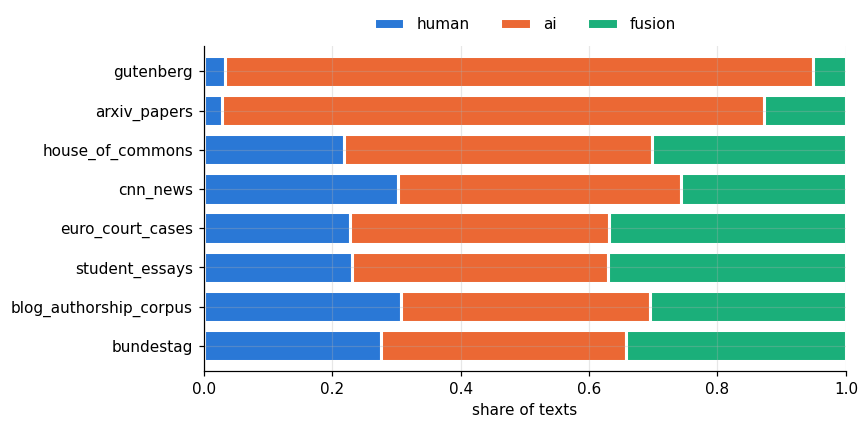

In [30]:
share = pd.crosstab(train.domain, train.label, normalize='index')[LABELS].sort_values('ai')
ax = share.plot.barh(stacked=True, color=[COLORS[l] for l in LABELS], width=.8, edgecolor='white', linewidth=2, figsize=(8, 4))
ax.set(xlabel='share of texts', ylabel=None, xlim=(0, 1))
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(.5, 1), frameon=False)
save('class_balance')

## Length distributions

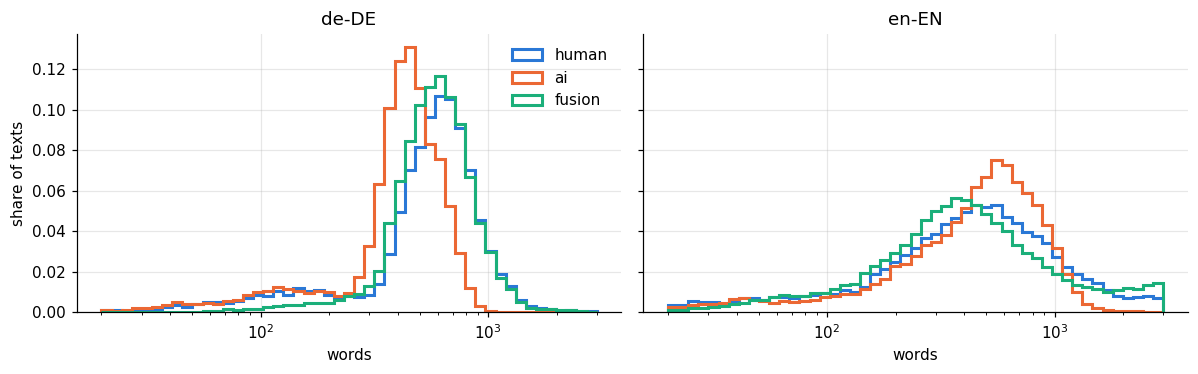

In [31]:
bins = np.logspace(np.log10(20), np.log10(3000), 50)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (lang, d) in zip(axes, train.groupby('lang')):
    for l in LABELS:
        x = d.loc[d.label == l, 'n_words']
        ax.hist(x, bins=bins, weights=np.ones(len(x)) / len(x), histtype='step', linewidth=2, color=COLORS[l], label=l)
    ax.set(xscale='log', title=lang, xlabel='words')
axes[0].set_ylabel('share of texts')
axes[0].legend(frameon=False)
save('lengths')

## AI markers heatmap

Color is normalized per row (share / row max), numbers are actual shares.

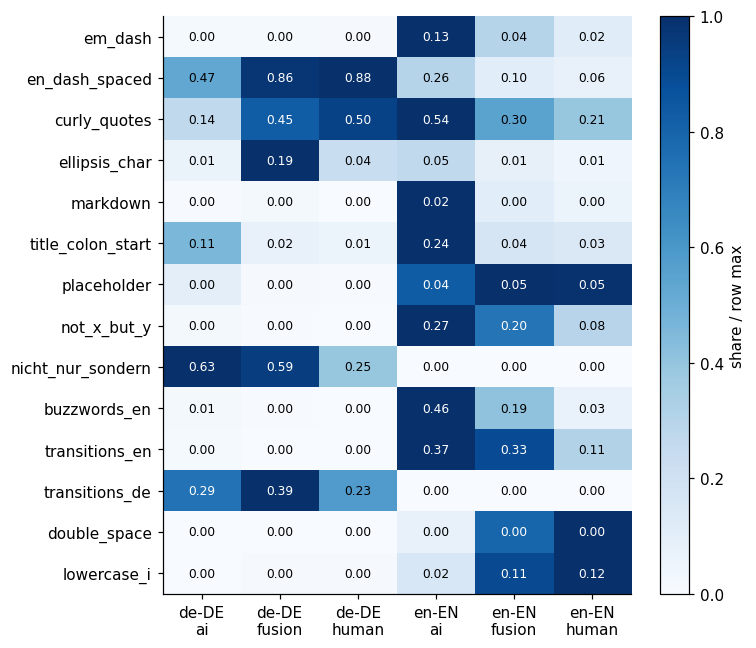

In [32]:
m = flags.groupby(['lang', 'label'])[list(MARKERS)].mean().T
m = m[m.max(axis=1) > 0]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(m.div(m.max(axis=1), axis=0), cmap='Blues', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(m.shape[1]), [f'{a}\n{b}' for a, b in m.columns])
ax.set_yticks(range(len(m)), m.index)
ax.grid(False)
for (i, j), v in np.ndenumerate(m.values):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v / m.values[i].max() > .6 else 'black')
fig.colorbar(im, ax=ax, label='share / row max')
save('markers')

## TF-IDF point clouds

Balanced sample: up to 250 texts per (domain, label). Vectorizers are fitted on this sample only, for visualization. t-SNE keeps local neighborhoods, global distances are not meaningful.

In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE

cloud = (train.groupby(['domain', 'label'], group_keys=False)
         .apply(lambda d: d.sample(min(len(d), 250), random_state=42))
         .reset_index(drop=True))

def embed(vec):
    X = TruncatedSVD(50, random_state=42).fit_transform(vec.fit_transform(cloud.text))
    return TSNE(2, init='pca', random_state=42).fit_transform(X)

emb = {
    'word': embed(TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50_000, sublinear_tf=True)),
    'char': embed(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), min_df=3, max_features=50_000, sublinear_tf=True)),
}
len(cloud)

5997

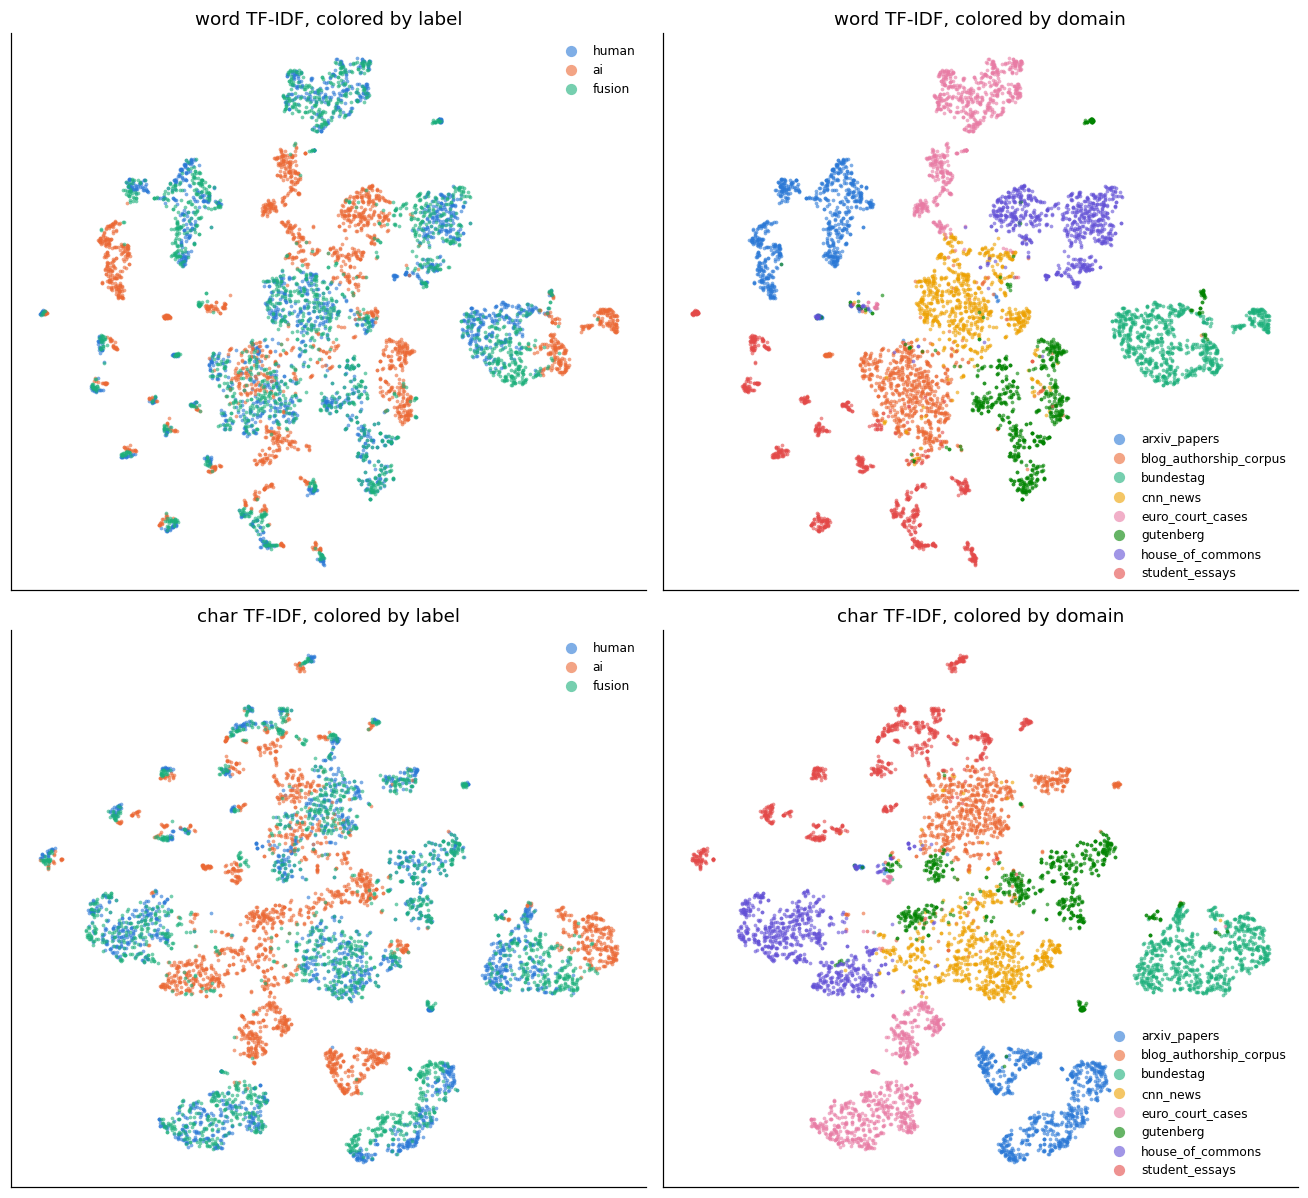

In [34]:
def scatter(ax, xy, groups, colors):
    groups = np.asarray(groups)
    for g, c in colors.items():
        ax.scatter(*xy[groups == g].T, s=6, alpha=.6, color=c, label=g, linewidths=0)
    ax.set(xticks=[], yticks=[])
    ax.legend(frameon=False, markerscale=3, fontsize=8)

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for row, (name, xy) in zip(axes, emb.items()):
    scatter(row[0], xy, cloud.label, COLORS)
    row[0].set_title(f'{name} TF-IDF, colored by label')
    scatter(row[1], xy, cloud.domain, DOMAIN_COLORS)
    row[1].set_title(f'{name} TF-IDF, colored by domain')
save('tfidf_clouds')

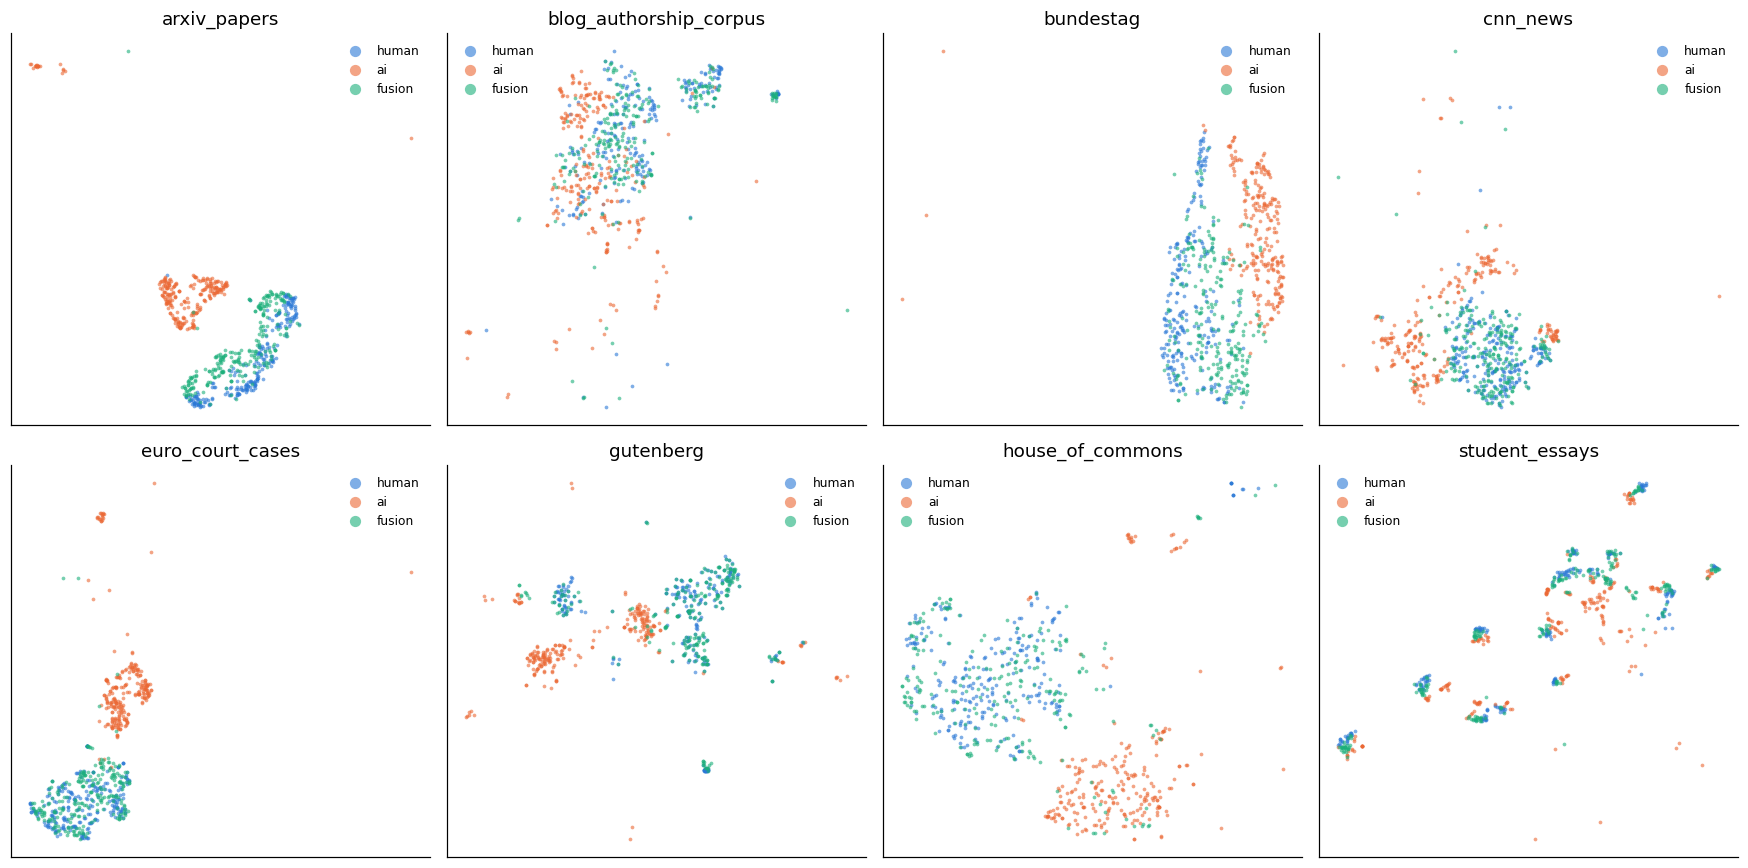

In [35]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (dom, d) in zip(axes.flat, cloud.groupby('domain')):
    scatter(ax, emb['char'][d.index], d.label, COLORS)
    ax.set_title(dom)
save('tfidf_clouds_by_domain')

## Feature correlations with label
Spearman correlation of every feature with one-hot label (robust to skewed lengths). Rows sorted by max |corr|.

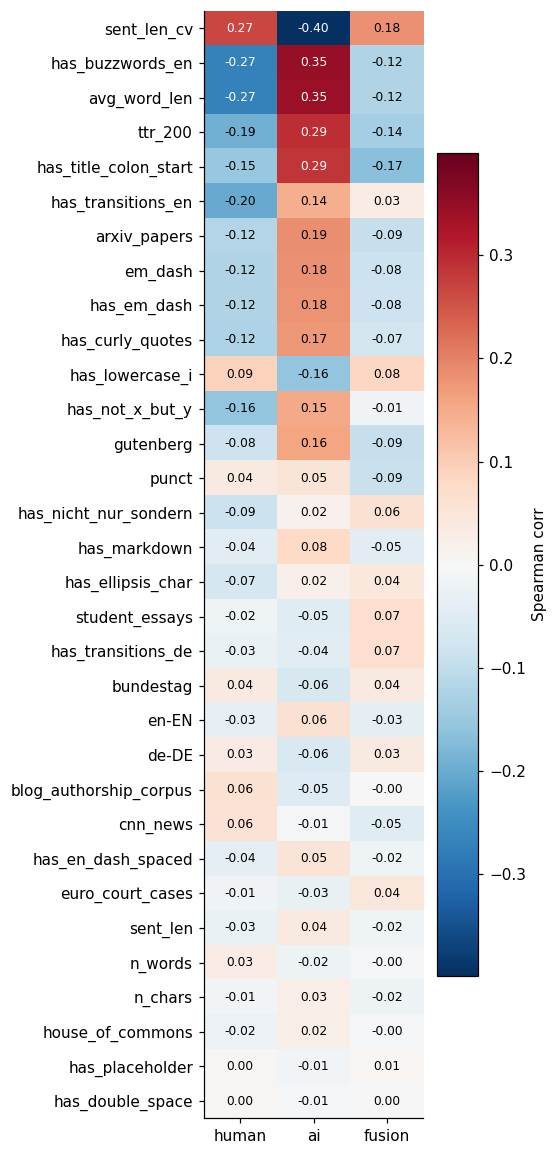

In [36]:
feats = pd.concat([
    train[['n_chars', 'n_words', 'avg_word_len', 'sent_len_cv']],
    style.drop(columns=['lang', 'label', 'newlines']),
    flags[list(MARKERS)].add_prefix('has_').astype(int),
    pd.get_dummies(train[['lang', 'domain']], prefix='', prefix_sep='').astype(int),
], axis=1)
target = pd.get_dummies(train.label)[LABELS].astype(int)
corr = pd.concat([feats, target], axis=1).corr(method='spearman').loc[feats.columns, LABELS]
corr = corr.dropna()
corr = corr.loc[corr.abs().max(axis=1).sort_values(ascending=False).index]

lim = corr.abs().values.max()
fig, ax = plt.subplots(figsize=(5, .3 * len(corr) + 1))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(len(LABELS)), LABELS)
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for (i, j), v in np.ndenumerate(corr.values):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > lim * .6 else 'black')
fig.colorbar(im, ax=ax, label='Spearman corr')
save('feature_label_corr')

# Human ↔ fusion pair analysis
Word-level diff between a human text and its fusion rewrite (sample of 1500 pairs).: how much, where and what the LLM changes.

In [37]:
import difflib
from collections import Counter

import matplotlib.pyplot as plt

PAIRS_N = 1500
prep = train
TOK = re.compile(r'\w+|[^\w\s]')

hum = prep[prep.label == 'human'].drop_duplicates('group').set_index('group')
fus = prep[prep.label == 'fusion'].drop_duplicates('group').set_index('group')
pairs = hum[['text', 'lang', 'domain']].join(fus[['text']], rsuffix='_f', how='inner')
pairs = pairs[pairs.text.str.split().str.len() >= 50]
pairs = pairs.sample(min(len(pairs), PAIRS_N), random_state=SEED)

ins = {lang: Counter() for lang in pairs.lang.unique()}
dels = {lang: Counter() for lang in pairs.lang.unique()}

def diff(h, f, lang):
    a, b = TOK.findall(h), TOK.findall(f)
    changed = np.zeros(len(a), bool)
    spans, first = 0, None
    for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=True).get_opcodes():
        if tag == 'equal':
            continue
        spans += 1
        first = i1 if first is None else first
        changed[i1:max(i2, i1 + 1)] = True
        dels[lang].update(w.lower() for w in a[i1:i2])
        ins[lang].update(w.lower() for w in b[j1:j2])
    bins = np.array_split(changed, 10)
    return {
        'changed': changed.mean(),
        'first_change': (len(a) if first is None else first) / len(a),
        'spans': spans,
        'len_ratio': len(b) / len(a),
        **{f'd{k}': x.mean() for k, x in enumerate(bins)},
    }

stats = pd.DataFrame([diff(h, f, l) for h, f, l in zip(pairs.text, pairs.text_f, pairs.lang)], index=pairs.index).join(pairs[['lang', 'domain']])
len(stats)

1500

## How much is changed

In [38]:
COLS = ['changed', 'first_change', 'spans', 'len_ratio']
pd.concat({
    'lang': stats.groupby('lang')[COLS].median(),
    'domain': stats.groupby('domain')[COLS].median(),
}).round(3)

changed  first_change  spans  len_ratio
lang   de-DE                     0.293         0.422    7.0      0.975
       en-EN                     0.352         0.435    5.0      0.852
domain arxiv_papers              0.452         0.461   18.0      0.784
       blog_authorship_corpus    0.305         0.484    3.0      0.821
       bundestag                 0.293         0.422    7.0      0.975
       cnn_news                  0.329         0.441    5.0      0.809
       euro_court_cases          0.314         0.384    8.0      0.929
       gutenberg                 0.413         0.000   14.0      0.811
       house_of_commons          0.427         0.325    6.0      0.756
       student_essays            0.381         0.418    5.0      0.884

## Where in the text

Share of human words changed, by position decile of the human text.

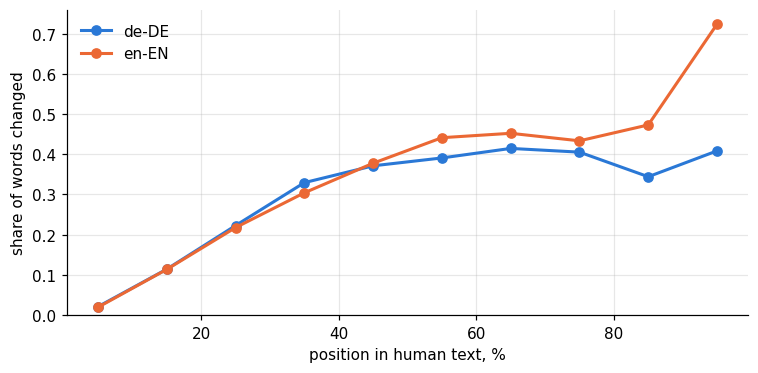

In [39]:
DECILES = [f'd{k}' for k in range(10)]
FIG = Path('figures')
FIG.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 3.5))
for (lang, d), color in zip(stats.groupby('lang'), ['#2a78d6', '#eb6834']):
    ax.plot(np.arange(5, 100, 10), d[DECILES].mean(), marker='o', linewidth=2, color=color, label=lang)
ax.set(xlabel='position in human text, %', ylabel='share of words changed', ylim=(0, None))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / 'fusion_change_profile.png', bbox_inches='tight')
plt.show()

## What is changed
Tokens the LLM adds vs removes (net count over sampled pairs).

In [40]:
def top_net(lang, n=25):
    net = pd.Series(ins[lang]).sub(pd.Series(dels[lang]), fill_value=0)
    return pd.DataFrame({
        'added_by_llm': [f'{w} {int(c):+d}' for w, c in net.nlargest(n).items()],
        'removed_by_llm': [f'{w} {int(c):+d}' for w, c in net.nsmallest(n).items()],
    })

pd.concat({lang: top_net(lang) for lang in ins}, axis=1)

de-DE                             en-EN               
              added_by_llm removed_by_llm       added_by_llm removed_by_llm
0                 die +484        . -1210             \ +287      the -9958
1              müssen +405       das -959         these +236        . -9264
2                  zu +387         , -870           our +208        , -5438
3             sondern +314       sie -666         legal +152       to -3934
4                 nur +309         – -646   furthermore +118       of -3407
5              unsere +250       ich -594       crucial +117       in -2805
6                 wir +225       der -541     potential +113     that -2669
7                 uns +219     haben -384   significant +102      and -2626
8                 und +206         : -331          sense +91        a -2195
9   herausforderungen +182         - -301         within +89        i -2149
10           menschen +178      auch -282     challenges +86        ' -2068
11            unserer +144      noch -273    individuals +86       on -1991
12                  ! +142       mit -263              { +85       is -1884
13                ein +141        im -253              } +85       it -1642
14               eine +132       bei -247      essential +84        - -1362
15       gesellschaft +122      dann -241       concerns +83       be -1289
16                 um +117         ; -232     ultimately +83      was -1277
17       verantwortung +99      dank -226  understanding +82      for -1180
18       sicherstellen +89      aber -223       approach +78     have -1174
19              bürger +86       hat -222          often +78        ( -1001
20            lösungen +82       man -211      financial +77         ) -971
21             zukunft +82      wenn -206           this +77       not -964
22            brauchen +77        ja -183        process +75       had -898
23        gleichzeitig +76        in -179        despite +70       you -897
24       unterstützung +74     jetzt -177      regarding +69       are -815

## Example diff
Pair with median change rate, starting 40 tokens before the first change. `[-removed-]` `{+added+}`.

In [41]:
def render(h, f, n=2000):
    a, b = TOK.findall(h), TOK.findall(f)
    out = []
    for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=True).get_opcodes():
        if tag == 'equal':
            out += a[i1:i2]
            continue
        if i2 > i1:
            out.append('[-' + ' '.join(a[i1:i2]) + '-]')
        if j2 > j1:
            out.append('{+' + ' '.join(b[j1:j2]) + '+}')
    first = next((k for k, w in enumerate(out) if w.startswith(('[-', '{+'))), 0)
    return ' '.join(out[max(first - 40, 0):])[:n]

ex = (stats.changed - stats.changed.median()).abs().idxmin()
print(pairs.loc[ex, ['lang', 'domain']].to_dict(), stats[COLS].loc[ex].astype(float).round(3).to_dict())
print(render(pairs.loc[ex, 'text'], pairs.loc[ex, 'text_f']))

{'lang': 'en-EN', 'domain': 'cnn_news'} {'changed': 0.339, 'first_change': 0.388, 'spans': 9.0, 'len_ratio': 0.769}
. ' It was a struggle at first , I was throwing my arms everywhere and screaming but he had his hand over my mouth . It felt like quite a few minutes before I went to the floor . [-' I was face down and-] {+“ I could hear him breathing heavily behind me , ” she said . " Then , suddenly+} he [-was using my hair to bash-] {+grabbed me from behind and started punching me over and over again . I remember screaming but my voice felt so weak , like it was trapped inside+} my head [-on the floor really hard .-] {+. " Miss Wall described the attack as relentless , saying that Atkins wouldn ' t let go , even when she pretended to pass out in a desperate attempt to make him stop . " Every time+} I thought [-that was it , I thought I was going to die . Thug : Matthew Atkins arrives at Shrewsbury Crown Court where he admitted to unlawfully and maliciously wounding Katey Wall with int